In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# 1. Load data and verify structure and uniqueness of IDs (Requirements C2 and C3)
uds = pd.read_csv('../udslong_imputed.csv')
mri = pd.read_csv('../mriscanclean.csv')

print("Total number of UDS rows:", len(uds))
print("Total number of MRI rows:", len(mri))
print("Are there duplicate IDs in UDS?", uds["NACCID"].duplicated().any())
print("Are there duplicate IDs in MRI?", mri["NACCID"].duplicated().any())
print("Are IDs across both files completely identical and aligned?", mri["NACCID"].equals(uds["NACCID"]))


Total number of UDS rows: 1237
Total number of MRI rows: 1237
Are there duplicate IDs in UDS? False
Are there duplicate IDs in MRI? False
Are IDs across both files completely identical and aligned? True


In [10]:
# 2. Merge both datasets (UDS + MRI) based on subject ID
df_merged = pd.merge(uds, mri.drop(columns=['NACCUDSD']), on='NACCID', how='inner')
print("Sample size after multimodal merge:", len(df_merged))

Sample size after multimodal merge: 1237


In [11]:


# ==========================================
# 3. Data Quality Audit & Handling Special/Missing Codes (Task 5 & Requirement C4)
# ==========================================
# Define rules for special/invalid codes in UDS & MRI:
# EDUC > 36 (Code 99 = unknown)
# MOCATOTS > 30 (Code 88 = not administered / imputed > 30)
# ANIMALS >= 95 (Codes 95-98 = physical/cognitive inability or not administered)
# VEG >= 95 (Codes 95-98)
# TRAILA > 150 (Max valid time is 150s; 995-998 = inability/not administered)
# TRAILB > 300 (Max valid time is 300s; 995-998 = inability/not administered)
# MRI volumes <= 0

def audit_missing_and_invalid(df_in):
    rules = {
        'NACCAGE': (df_in['NACCAGE'] < 18) | (df_in['NACCAGE'] > 120),
        'SEX': ~df_in['SEX'].isin([1, 2]),
        'EDUC': df_in['EDUC'] > 36,
        'MOCATOTS': df_in['MOCATOTS'] > 30,
        'ANIMALS': df_in['ANIMALS'] >= 95,
        'VEG': df_in['VEG'] >= 95,
        'TRAILA': df_in['TRAILA'] > 150,
        'TRAILB': df_in['TRAILB'] > 300,
        'LH_ENTORHINAL_AVGTH': df_in['LH_ENTORHINAL_AVGTH'] <= 0,
        'RH_ENTORHINAL_AVGTH': df_in['RH_ENTORHINAL_AVGTH'] <= 0,
        'LH_PRECUNEUS_AVGTH': df_in['LH_PRECUNEUS_AVGTH'] <= 0,
        'RH_PRECUNEUS_AVGTH': df_in['RH_PRECUNEUS_AVGTH'] <= 0,
        'LH_ENTORHINAL_GVOL': df_in['LH_ENTORHINAL_GVOL'] <= 0,
    }
    report = []
    for var, cond in rules.items():
        n_inv = int(cond.sum())
        pct = round(n_inv / len(df_in) * 100, 2)
        report.append({'Variable': var, 'Invalid_Count': n_inv, 'Invalid_Percent (%)': pct})
    return pd.DataFrame(report)

print("\n--- Audit in Full Merged Dataset (N=1237) ---")
print(audit_missing_and_invalid(df_merged).to_string(index=False))

# Filter for Target Impaired Population: MCI (NACCUDSD == 3) and Dementia (NACCUDSD == 4)
df_impaired_raw = df_merged[df_merged['NACCUDSD'].isin([3.0, 4.0])].copy()
print(f"\n--- Audit in Target Impaired Subgroup (MCI & Dementia, N={len(df_impaired_raw)}) ---")
print(audit_missing_and_invalid(df_impaired_raw).to_string(index=False))

# Replace invalid codes with NaN across the dataset
df_clean = df_merged.copy()
df_clean.loc[df_clean['EDUC'] > 36, 'EDUC'] = np.nan
df_clean.loc[df_clean['MOCATOTS'] > 30, 'MOCATOTS'] = np.nan
df_clean.loc[df_clean['ANIMALS'] >= 95, 'ANIMALS'] = np.nan
df_clean.loc[df_clean['VEG'] >= 95, 'VEG'] = np.nan
df_clean.loc[df_clean['TRAILA'] > 150, 'TRAILA'] = np.nan
df_clean.loc[df_clean['TRAILB'] > 300, 'TRAILB'] = np.nan
df_clean.loc[df_clean['LH_ENTORHINAL_GVOL'] <= 0, 'LH_ENTORHINAL_GVOL'] = np.nan

# Extract cleaned Target Subgroup (MCI + Dementia)
df_target = df_clean[df_clean['NACCUDSD'].isin([3.0, 4.0])].copy()


--- Audit in Full Merged Dataset (N=1237) ---
           Variable  Invalid_Count  Invalid_Percent (%)
            NACCAGE              0                 0.00
                SEX              0                 0.00
               EDUC              2                 0.16
           MOCATOTS              9                 0.73
            ANIMALS             11                 0.89
                VEG             14                 1.13
             TRAILA             26                 2.10
             TRAILB             64                 5.17
LH_ENTORHINAL_AVGTH              0                 0.00
RH_ENTORHINAL_AVGTH              0                 0.00
 LH_PRECUNEUS_AVGTH              0                 0.00
 RH_PRECUNEUS_AVGTH              0                 0.00
 LH_ENTORHINAL_GVOL              1                 0.08

--- Audit in Target Impaired Subgroup (MCI & Dementia, N=383) ---
           Variable  Invalid_Count  Invalid_Percent (%)
            NACCAGE              0            

In [12]:
# ==========================================
# 4. Frequency Tables for Categorical Variables
# ==========================================
print("\n--- Frequency Table: Clinical Diagnosis (NACCUDSD) in Full Sample (N=1237) ---")
diag_counts = df_clean['NACCUDSD'].value_counts().sort_index()
diag_pct = (df_clean['NACCUDSD'].value_counts(normalize=True).sort_index() * 100).round(2)
print(pd.DataFrame({'Count': diag_counts, 'Percentage (%)': diag_pct}))

print("\n--- Frequency Table: Sex & Diagnosis in Target Impaired Sample (N=383) ---")
for col in ['NACCUDSD', 'SEX']:
    c_cnt = df_target[col].value_counts().sort_index()
    c_pct = (df_target[col].value_counts(normalize=True).sort_index() * 100).round(2)
    print(f"\n{col}:")
    print(pd.DataFrame({'Count': c_cnt, 'Percentage (%)': c_pct}))


--- Frequency Table: Clinical Diagnosis (NACCUDSD) in Full Sample (N=1237) ---
          Count  Percentage (%)
NACCUDSD                       
1.0         847           68.47
2.0           7            0.57
3.0         252           20.37
4.0         131           10.59

--- Frequency Table: Sex & Diagnosis in Target Impaired Sample (N=383) ---

NACCUDSD:
          Count  Percentage (%)
NACCUDSD                       
3.0         252            65.8
4.0         131            34.2

SEX:
     Count  Percentage (%)
SEX                       
1.0    191           49.87
2.0    192           50.13


In [13]:
# ==========================================
# 5. Central Tendency and Dispersion Summary 
# ==========================================
quant_vars = [
    'NACCAGE', 'EDUC', 'MOCATOTS', 'ANIMALS', 'VEG', 'TRAILA', 'TRAILB',
    'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH',
    'LH_PRECUNEUS_AVGTH', 'RH_PRECUNEUS_AVGTH', 'LH_ENTORHINAL_GVOL'
]

def summarize_quantitative(df_in, variables):
    summary_list = []
    for var in variables:
        s = df_in[var].dropna()
        q25, q50, q75 = np.percentile(s, [25, 50, 75])
        summary_list.append({
            'Variable': var,
            'Valid_N': len(s),
            'Missing_N': int(df_in[var].isna().sum()),
            'Mean': round(s.mean(), 2),
            'SD': round(s.std(), 2),
            'Median': round(q50, 2),
            'Q1': round(q25, 2),
            'Q3': round(q75, 2),
            'IQR': round(q75 - q25, 2),
            'Min': round(s.min(), 2),
            'Max': round(s.max(), 2)
        })
    return pd.DataFrame(summary_list)

print("\n--- Summary Statistics: Target Impaired Subgroup (MCI & Dementia, N=383) ---")
print(summarize_quantitative(df_target, quant_vars).to_string(index=False))

print("\n--- Summary Statistics: Full Dataset (N=1237) ---")
print(summarize_quantitative(df_clean, quant_vars).to_string(index=False))


--- Summary Statistics: Target Impaired Subgroup (MCI & Dementia, N=383) ---
           Variable  Valid_N  Missing_N    Mean     SD  Median      Q1      Q3    IQR    Min     Max
            NACCAGE      383          0   70.21   8.01   71.00   65.00   76.00  11.00  45.00   91.00
               EDUC      382          1   15.97   2.94   16.00   14.00   18.00   4.00   0.00   20.00
           MOCATOTS      379          4   20.40   5.28   22.00   18.00   24.00   6.00   0.00   30.00
            ANIMALS      376          7   15.98   6.06   16.00   12.00   19.25   7.25   1.00   35.00
                VEG      373         10   10.17   4.10   10.00    7.00   13.00   6.00   0.00   25.00
             TRAILA      362         21   46.99  29.92   38.00   29.00   52.00  23.00  11.00  150.00
             TRAILB      325         58  138.58  80.77  109.00   78.00  163.00  85.00  33.00  300.00
LH_ENTORHINAL_AVGTH      383          0    2.80   0.43    2.84    2.51    3.10   0.59   1.28    3.98
RH_ENTORHINAL

In [14]:
# ==========================================
# 6. Descriptive Group Comparison Across Clinical Stages (Task 9 & Requirement C4)
# ==========================================
df_3groups = df_clean[df_clean['NACCUDSD'].isin([1.0, 3.0, 4.0])].copy()
print("\n--- Group Comparison: Normal (1) vs. MCI (3) vs. Dementia (4) ---")
for var in ['NACCAGE', 'EDUC', 'MOCATOTS', 'ANIMALS', 'TRAILA', 'TRAILB', 'LH_ENTORHINAL_AVGTH', 'LH_PRECUNEUS_AVGTH']:
    grp = df_3groups.groupby('NACCUDSD')[var].agg(
        N='count',
        Mean='mean',
        SD='std',
        Median='median',
        IQR=lambda x: np.percentile(x.dropna(), 75) - np.percentile(x.dropna(), 25)
    ).round(2)
    print(f"\nVariable: {var}")
    print(grp)


--- Group Comparison: Normal (1) vs. MCI (3) vs. Dementia (4) ---

Variable: NACCAGE
            N   Mean    SD  Median   IQR
NACCUDSD                                
1.0       847  67.27  7.92    67.0   9.0
3.0       252  70.83  7.44    71.0  10.0
4.0       131  69.02  8.90    70.0  14.0

Variable: EDUC
            N   Mean    SD  Median  IQR
NACCUDSD                               
1.0       846  16.38  2.61    16.0  3.0
3.0       251  16.09  2.93    16.0  4.0
4.0       131  15.75  2.97    16.0  4.0

Variable: MOCATOTS
            N   Mean    SD  Median  IQR
NACCUDSD                               
1.0       842  26.17  2.36    26.2  3.0
3.0       251  22.40  3.38    23.0  5.0
4.0       128  16.48  6.10    17.0  8.0

Variable: ANIMALS
            N   Mean    SD  Median   IQR
NACCUDSD                                
1.0       843  22.32  5.43    22.0  8.00
3.0       250  17.85  5.56    17.0  7.00
4.0       126  12.27  5.26    12.0  6.75

Variable: TRAILA
            N   Mean     SD  Me

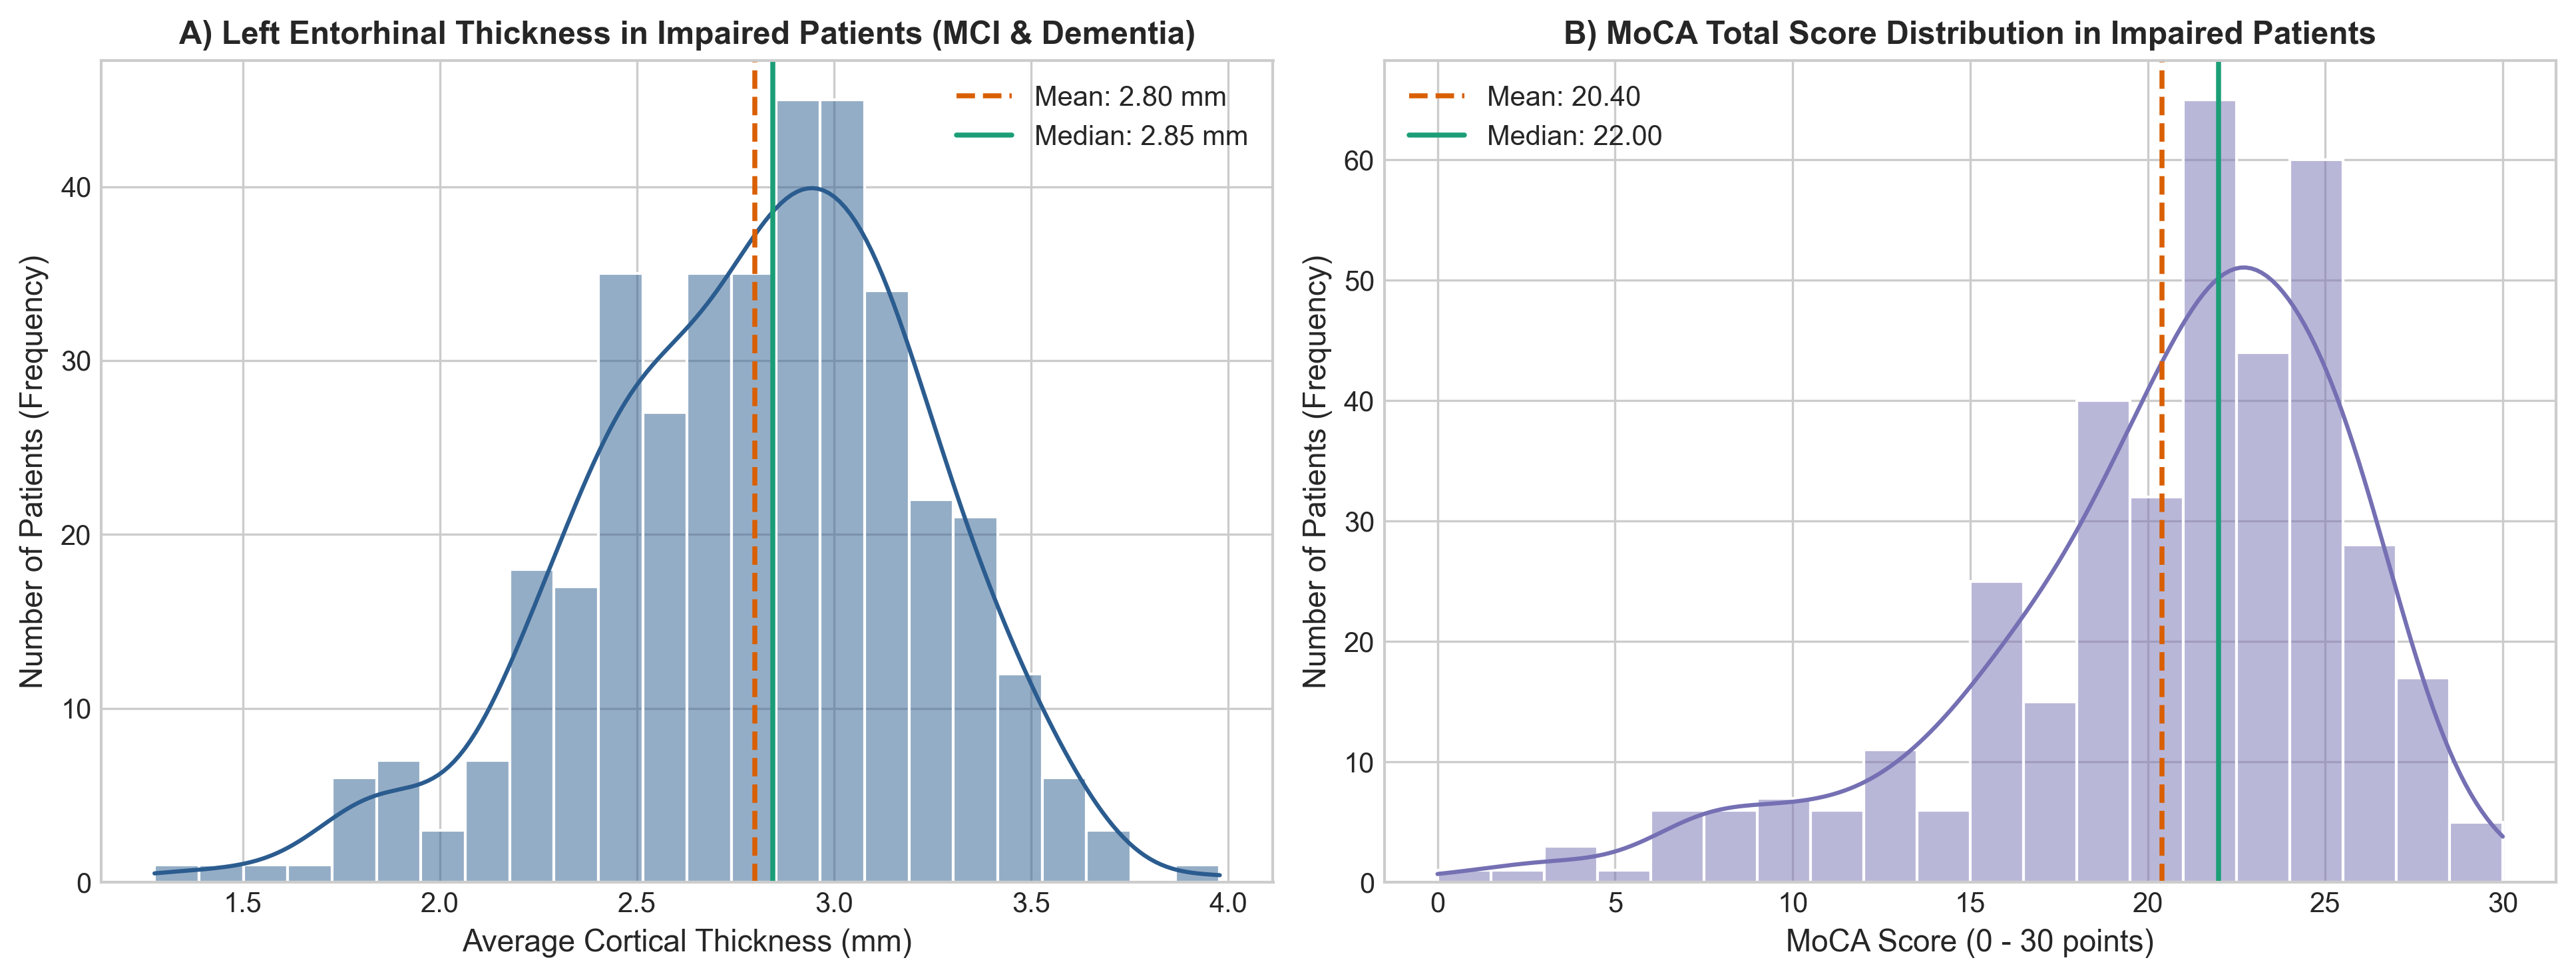

C:\Users\lenovo\AppData\Local\Temp\ipykernel_12200\1926424069.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_3groups, x='Diag_Group', y='LH_PRECUNEUS_AVGTH', order=order_diag, palette=palette_diag, width=0.45, ax=axes[1])


<Figure size 640x480 with 0 Axes>

C:\Users\lenovo\AppData\Local\Temp\ipykernel_12200\1926424069.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_3groups, x='Diag_Group', y='ANIMALS', order=order_diag, palette=palette_diag, width=0.45, ax=axes[0])
C:\Users\lenovo\AppData\Local\Temp\ipykernel_12200\1926424069.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_3groups, x='Diag_Group', y='TRAILB', order=order_diag, palette=palette_diag, width=0.45, ax=axes[1])


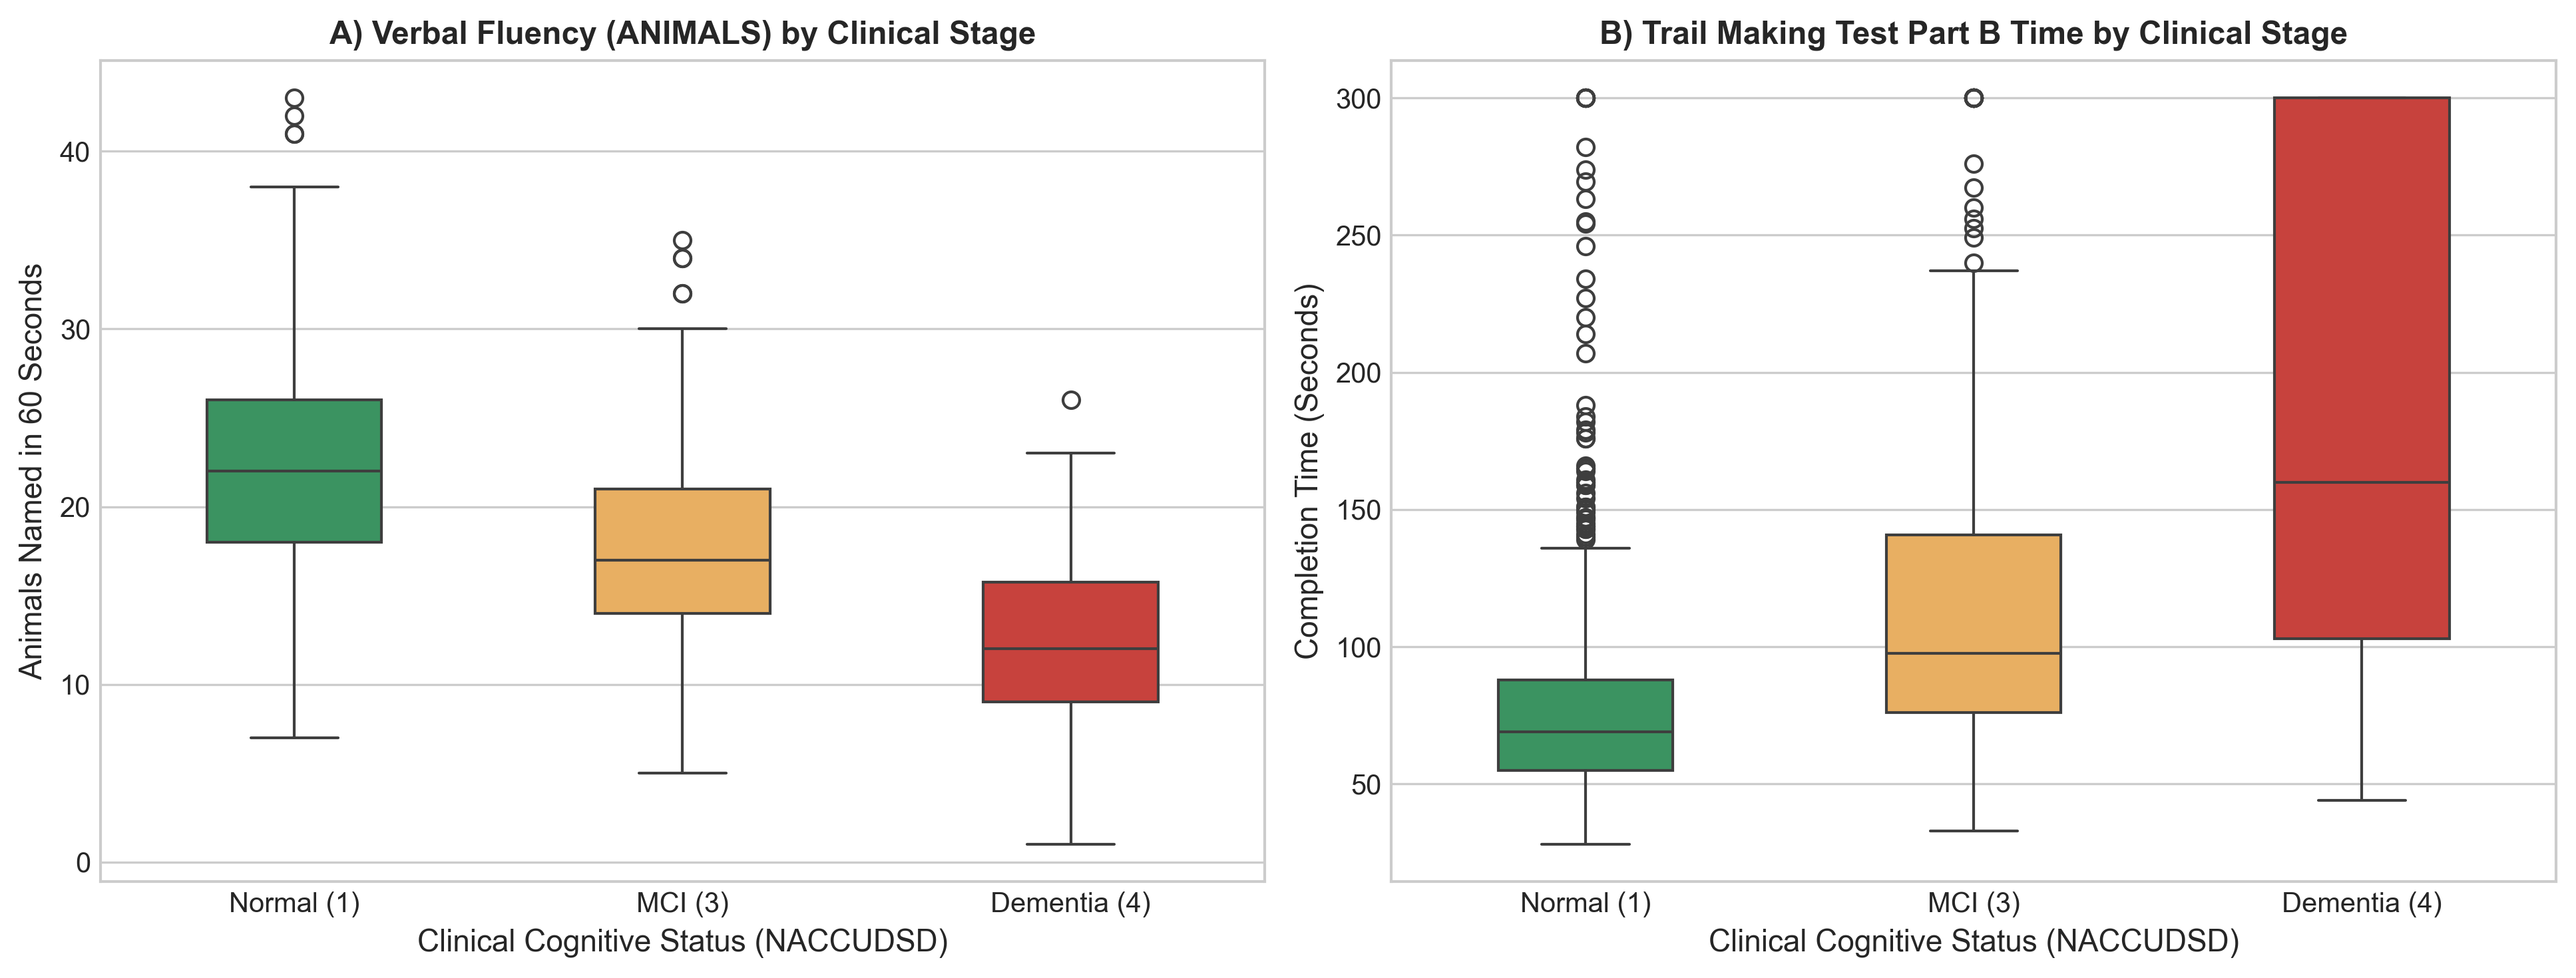

In [15]:
# ==========================================
# 7. Visualizations (Task 8 & Requirement C5)
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')
df_3groups['Diag_Group'] = df_3groups['NACCUDSD'].map({1.0: 'Normal (1)', 3.0: 'MCI (3)', 4.0: 'Dementia (4)'})
df_target['Diag_Group'] = df_target['NACCUDSD'].map({3.0: 'MCI (3)', 4.0: 'Dementia (4)'})
order_diag = ['Normal (1)', 'MCI (3)', 'Dementia (4)']
palette_diag = ['#2ca25f', '#feb24c', '#de2d26']

# Figure 1: Histograms + KDE of Left Entorhinal Thickness & MoCA Score in Impaired Patients
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
sns.histplot(df_target['LH_ENTORHINAL_AVGTH'].dropna(), kde=True, ax=axes[0], color='#2b5c8f', bins=24, edgecolor='white')
axes[0].axvline(df_target['LH_ENTORHINAL_AVGTH'].mean(), color='#d95f02', linestyle='--', linewidth=1.8, label=f"Mean: {df_target['LH_ENTORHINAL_AVGTH'].mean():.2f} mm")
axes[0].axvline(df_target['LH_ENTORHINAL_AVGTH'].median(), color='#1b9e77', linestyle='-', linewidth=1.8, label=f"Median: {df_target['LH_ENTORHINAL_AVGTH'].median():.2f} mm")
axes[0].set_title('A) Left Entorhinal Thickness in Impaired Patients (MCI & Dementia)', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Average Cortical Thickness (mm)', fontsize=11)
axes[0].set_ylabel('Number of Patients (Frequency)', fontsize=11)
axes[0].legend()

sns.histplot(df_target['MOCATOTS'].dropna(), kde=True, ax=axes[1], color='#7570b3', bins=20, edgecolor='white')
axes[1].axvline(df_target['MOCATOTS'].mean(), color='#d95f02', linestyle='--', linewidth=1.8, label=f"Mean: {df_target['MOCATOTS'].mean():.2f}")
axes[1].axvline(df_target['MOCATOTS'].median(), color='#1b9e77', linestyle='-', linewidth=1.8, label=f"Median: {df_target['MOCATOTS'].median():.2f}")
axes[1].set_title('B) MoCA Total Score Distribution in Impaired Patients', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('MoCA Score (0 - 30 points)', fontsize=11)
axes[1].set_ylabel('Number of Patients (Frequency)', fontsize=11)
axes[1].legend()
plt.tight_layout()
plt.savefig('img/phase1_fig1_histograms.png', dpi=300)
plt.show()

# Figure 2: Violin & Boxplot of Cortical Thickness across Clinical Stages
sns.boxplot(data=df_3groups, x='Diag_Group', y='LH_PRECUNEUS_AVGTH', order=order_diag, palette=palette_diag, width=0.45, ax=axes[1])
axes[1].set_title('B) Left Precuneus Cortical Thickness by Clinical Stage', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Clinical Cognitive Status (NACCUDSD)', fontsize=11)
axes[1].set_ylabel('Cortical Thickness (mm)', fontsize=11)
plt.tight_layout()
plt.savefig('img/phase1_fig2_mri_by_stage.png', dpi=300)
plt.show()

# Figure 3: Boxplots of Cognitive Scores across Clinical Stages
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
sns.boxplot(data=df_3groups, x='Diag_Group', y='ANIMALS', order=order_diag, palette=palette_diag, width=0.45, ax=axes[0])
axes[0].set_title('A) Verbal Fluency (ANIMALS) by Clinical Stage', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Clinical Cognitive Status (NACCUDSD)', fontsize=11)
axes[0].set_ylabel('Animals Named in 60 Seconds', fontsize=11)

sns.boxplot(data=df_3groups, x='Diag_Group', y='TRAILB', order=order_diag, palette=palette_diag, width=0.45, ax=axes[1])
axes[1].set_title('B) Trail Making Test Part B Time by Clinical Stage', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Clinical Cognitive Status (NACCUDSD)', fontsize=11)
axes[1].set_ylabel('Completion Time (Seconds)', fontsize=11)
plt.tight_layout()
plt.savefig('img/phase1_fig3_cognition_boxplots.png', dpi=300)
plt.show()